In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

import seaborn as sns

import torch
import torchaudio
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display

In [2]:
def compute_cllr(scores, labels):
    scores = np.array(scores)
    labels = np.array(labels)
    tar = scores[labels == 1]
    non = scores[labels == 0]
    c1 = np.mean(np.log2(1 + np.exp(-tar)))
    c2 = np.mean(np.log2(1 + np.exp(non)))
    return (c1 + c2) / 2

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)
    cllr = compute_cllr(scores, labels)
    
    preds = (scores >= 0).astype(int)
    
    bacc = balanced_accuracy_score(preds, labels)
    acc = accuracy_score(preds, labels)
    prec = precision_score(labels, preds)
    rec = recall_score(labels, preds)
    f1 = f1_score(labels, preds)

    header = f"{'AUC%':>8} {'EER%':>8} {'Cllr':>8} {'B.Acc.':>8} {'Acc.':>8} {'Prec.':>8} {'Recall':>8} {'F1':>8}"
    print(header)
    print(f"{rocauc*100:>8.2f} "
          f"{eer*100:>8.2f} "
          f"{cllr:>8.4f} "
          f"{bacc*100:>8.2f} "
          f"{acc*100:>8.2f} "
          f"{prec*100:>8.2f} "
          f"{rec*100:>8.2f} "
          f"{f1*100:>8.2f}")

def load_results(path):
    logLR_scores = np.load(os.path.join(path, "scores_per_expert.npy"))
    labels = np.load(os.path.join(path, "labels.npy"))
    attack_ids = np.load(os.path.join(path, "attack_ids.npy"))
    return logLR_scores, labels, attack_ids
    
def plot_distributions(real_scores, fake_scores, lbound=None, hbound=None, thr=0, ax=None, metrics=True):

    labels = np.concatenate([
        np.zeros(len(real_scores)),
        np.ones(len(fake_scores))
    ])
    
    if metrics:
        print_metrics(np.concatenate([real_scores, fake_scores]), labels)
        print()
        print(f"   Real mean score: {real_scores.mean():.4f}")
        print(f"   Fake mean score: {fake_scores.mean():.4f}\n")
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    #sns.histplot(real_scores, bins=50, stat="count", kde=False, color='blue', alpha=0.4, label="Real (0)", ax=ax)
    #sns.histplot(fake_scores, bins=50, stat="count", kde=False, color='orange', alpha=0.4, label="Fake (1)", ax=ax)

    ax.axvline(thr, linestyle="--", linewidth=2, color="red")
    
    if lbound is not None:
        ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
        
    ax.legend() 
    
def show_per_attack_per_expert(scores, labels, attack_ids, selected_attack=None, show_metrics=False):
    print("\n#--------- PER ATTACK, PER EXPERT ---------#\n")
    # SEPARATE SCORES FOR REAL AND SCORES FOR FAKES, FOR EVERY EXPERT

    n_exp = scores.shape[0]

    attack_ids = attack_ids.squeeze()
    labels = labels.squeeze()
    real_mask = (labels == 0)
    fake_mask = ~real_mask

    real_scores = {
        exp: scores[exp, real_mask]
        for exp in range(n_exp)
    }

    if selected_attack:
        unique_attacks = np.array(selected_attack)
    else:
        unique_attacks = np.unique(attack_ids)
        
    unique_attacks = unique_attacks[unique_attacks != '-']  # remove real
    attack_scores = {
        a: {
            exp: scores[exp, (attack_ids == a) & fake_mask]
            for exp in range(n_exp)
        }
        for a in unique_attacks
    }
    

    # PLOT DISTRIBUTIONS ON EVERY ATTACK, FOR EACH EXPERT (ALL REAL SAMPLES vs FAKE SCORES ON THE GIVEN ATTACK)
  
    n_att = len(unique_attacks)
    n_exp = scores.shape[0]
    
    fig, axes = plt.subplots(n_att, n_exp, figsize=(5*n_exp, 3*n_att))
    
    thr = 0
    lbound = np.percentile(scores, 5)
    hbound = np.percentile(scores, 95)
    
    for i, a in enumerate(unique_attacks):
        for exp in range(n_exp):
            ax = axes[i, exp] if n_att > 1 else axes[exp]
    
            real_exp_scores = real_scores[exp]
            fake_exp_scores = attack_scores[a][exp]
    
            plot_distributions(
                real_exp_scores,
                fake_exp_scores,
                lbound,
                hbound,
                thr=thr,
                ax=ax,
                metrics=show_metrics
            )
    
            if i == 0:
                ax.set_title(f"Exp {exp}")
            if exp == 0:
                ax.set_ylabel(f"{a}")
    
    plt.tight_layout()
    plt.show()

def show_ensemble(scores, labels): 
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    sum_logLR_scores = np.sum(scores, axis=0)
    real_ens_scores = sum_logLR_scores[labels == 0]
    fake_ens_scores = sum_logLR_scores[labels == 1]

    plot_distributions(real_ens_scores, fake_ens_scores, metrics=True)
    plt.show()  

In [3]:
def select_samples_by_score(
    scores,
    labels,
    attack_ids,
    rootpath,
    expert_id,
    attack,
    min_score=-np.inf,
    max_score=np.inf,
    pick_fakes=True,
    limit=None,
):
    """
    Returns filenames (and indices) for samples matching:
    - given expert
    - given attack
    - score range [min_score, max_score]
    """

    filenames = np.load(f"{rootpath}/filenames.npy")
    attack_ids = attack_ids.squeeze()
    labels = labels.squeeze()

    # expert scores
    exp_scores = scores[expert_id]

    if pick_fakes:
        # fake samples only 
        mask = labels != 0
        # mask for selected attack
        attack_mask = (attack_ids == attack)
    else:
        mask = labels == 0

    # score range mask
    score_mask = (exp_scores >= min_score) & (exp_scores <= max_score)

    if pick_fakes:
        final_mask = mask & attack_mask & score_mask
    else:
        final_mask = mask & score_mask

    indices = np.where(final_mask)[0]

    if limit is not None:
        indices = indices[:limit]

    selected_files = filenames[indices]
    return indices, selected_files, exp_scores[indices]

def show_audio_and_spectrogram(
    path,
    sr=16000,
    trim=False,
    normalize=False,
    windowing=False
):
    # --- load ---
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.tensor(waveform).float()

    # --- resample ---
    if sample_rate != sr:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform.unsqueeze(0)).squeeze(0)

    # --- normalize ---
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak

    # --- trim ---
    if trim:
        top_db = 40
        thr = 10 ** (-top_db / 20)
        idx = (waveform.abs() > thr).nonzero(as_tuple=True)[0]
        if idx.numel() > 0:
            waveform = waveform[idx[0]:idx[-1] + 1]

    # --- optional windowing ---
    if windowing:
        waveform = prepare_audio_window(waveform)

    # --- spectrogram ---
    spec = torchaudio.transforms.Spectrogram(
        n_fft=512,
        hop_length=256,
        power=2
    )(waveform.unsqueeze(0)).squeeze(0)

    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )

    # --- plot ---
    plt.figure(figsize=(10, 4))
    plt.imshow(spec_db.numpy(), aspect="auto", origin="lower")
    plt.title(path.split("/")[-1])
    plt.colorbar()
    plt.tight_layout()
    plt.show()

    # --- audio player ---
    display(Audio(waveform.numpy(), rate=sr))

# ASVspoof 2019


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   84.91    23.88   0.7120    60.13    66.33    97.82    63.74    77.19

   Real mean score: -0.8564
   Fake mean score: 0.6795



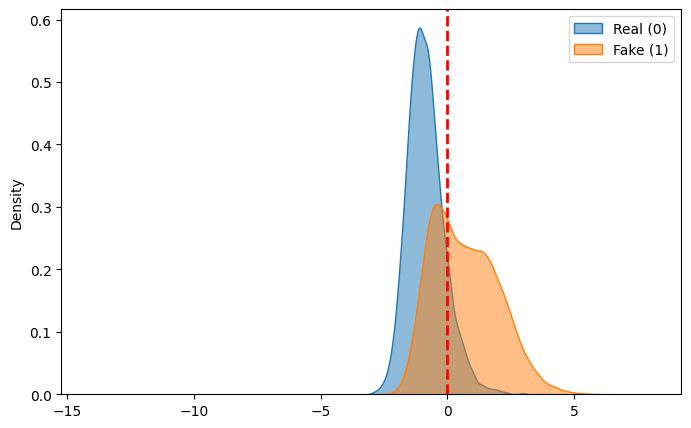

In [4]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_pooled_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
show_ensemble(scores, labels)


#--------- PER ATTACK, PER EXPERT ---------#



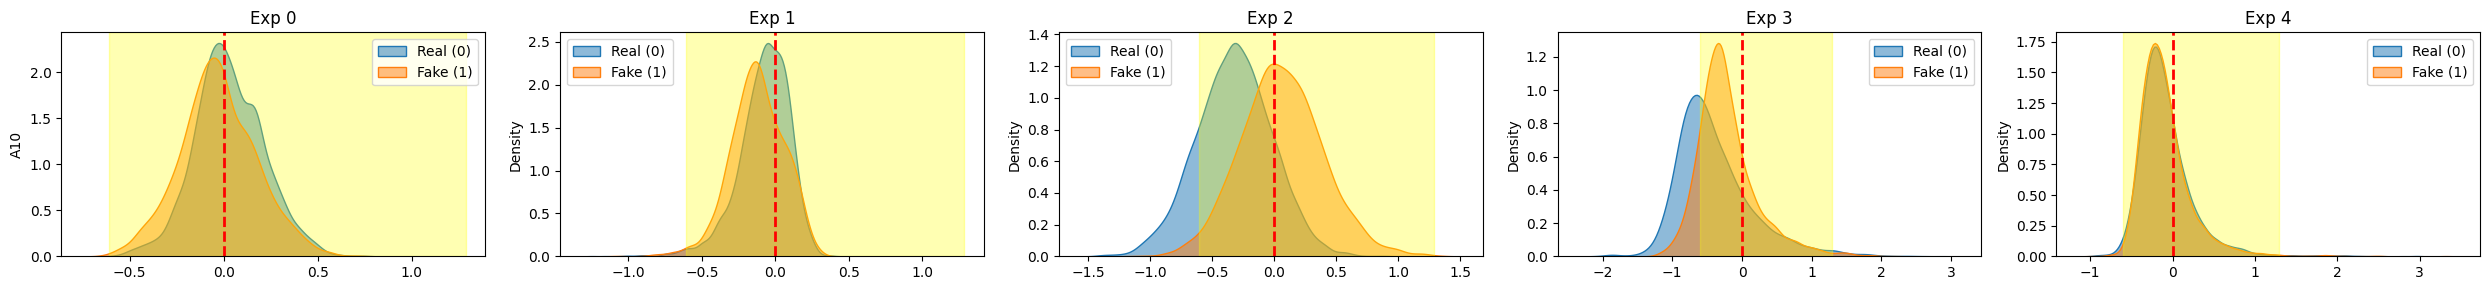

In [94]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_pooled_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
selected_attacks = ['A10']
show_per_attack_per_expert(scores, labels, attack_ids, selected_attacks, show_metrics=False)

In [95]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_pooled_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
indices, files, selected_scores = select_samples_by_score(
    scores, labels, attack_ids, rootpath,
    expert_id=2,     # expert index
    attack='A10',
    min_score=0.5,
    max_score=1,
    pick_fakes=True,
    limit=5
)

root_audio = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"
full_paths = np.array([
    os.path.join(root_audio, f + '.flac') for f in files
])

for idx, (p, s) in enumerate(zip(full_paths, selected_scores)):
    print(idx, s, p)

0 0.8250471436531293 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_7551608.flac
1 0.5905992910819426 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_2407543.flac
2 0.7424952109817039 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_7350340.flac
3 0.5661943382457773 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_5305862.flac
4 0.550079378423878 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_6842104.flac


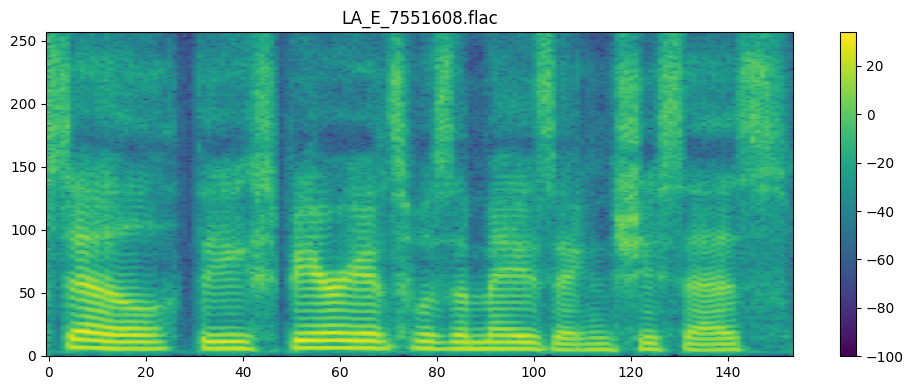

In [97]:
show_audio_and_spectrogram(full_paths[0])

## ASVspoof 5


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   58.91    43.85   1.0338    52.31    34.69    92.04    28.86    43.94

   Real mean score: -0.5212
   Fake mean score: -0.2018



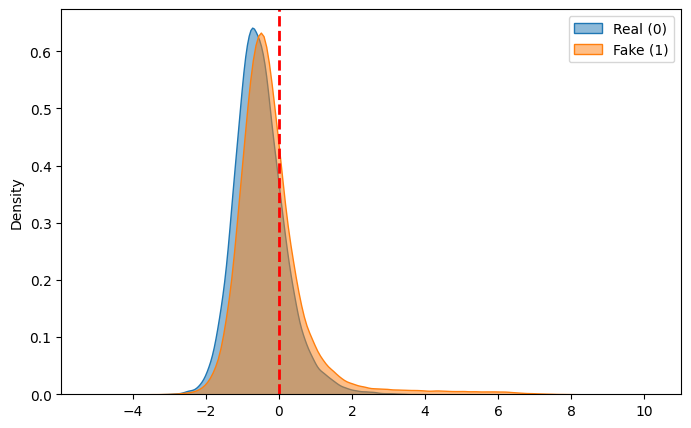

In [10]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/5_experts_FULL_EVAL/Cset_ASV19_pooled"
scores, labels, attack_ids = load_results(rootpath)
show_ensemble(scores, labels)


#--------- PER ATTACK, PER EXPERT ---------#



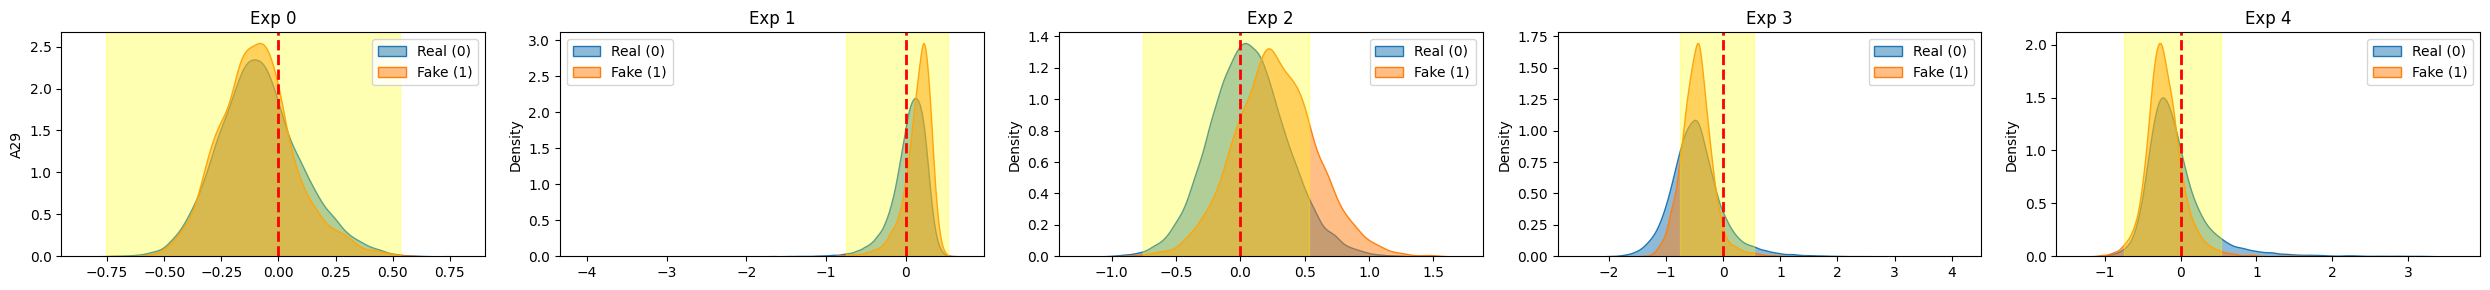

In [74]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/5_experts_FULL_EVAL/Cset_ASV19_pooled"
scores, labels, attack_ids = load_results(rootpath)
selected_attacks = ['A29']
show_per_attack_per_expert(scores, labels, attack_ids, selected_attacks, show_metrics=False)

In [77]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/5_experts_FULL_EVAL/Cset_ASV19_pooled"
scores, labels, attack_ids = load_results(rootpath)
indices, files, selected_scores = select_samples_by_score(
    scores, labels, attack_ids, rootpath,
    expert_id=2,     # expert index
    attack='A29',
    min_score=1.25,
    max_score=1.5,
    pick_fakes=True,
    limit=5
)

root_audio = "/Database/ASVspoof5/flac_E_eval"
full_paths = np.array([
    os.path.join(root_audio, f + '.flac') for f in files
])

for idx, (p, s) in enumerate(zip(full_paths, selected_scores)):
    print(idx, s, p)

0 1.255976842305722 /Database/ASVspoof5/flac_E_eval/E_0007074587.flac
1 1.350340869163343 /Database/ASVspoof5/flac_E_eval/E_0004349475.flac
2 1.2732264831485904 /Database/ASVspoof5/flac_E_eval/E_0002964340.flac
3 1.2621368522474525 /Database/ASVspoof5/flac_E_eval/E_0002443154.flac
4 1.2688505608257319 /Database/ASVspoof5/flac_E_eval/E_0003067118.flac


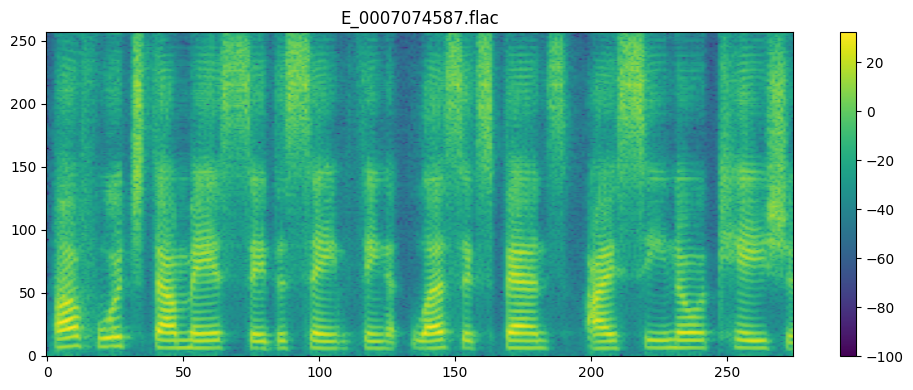

In [78]:
show_audio_and_spectrogram(full_paths[0])